# Relativistic disks and continuum reverberation

Changes in the irradiating luminosity produce a delayed thermal response across the disk. `KerrDiskModel` calculates this response with or without microlensing. Omit `driving_signal` to construct a static disk. To retain a driven disk's mean lamp heating while disabling fluctuations in a microlensing calculation, use `system.light_curve(..., apply_driving_signal=False)`. Explicit `True` requires a source with a driver. The driver can inherit the system's variability seed, or specify its own seed for standalone source calculations.


This tutorial constructs three reusable products.  A Kerr ray trace maps an
equatorial disk to the observer, including capture, light bending, Doppler and
gravitational shifts, emission azimuth, and observer-frame delay.  An axial
lamppost supplies the disk-heating response.  Finally, a ten-year sequence of
production IPM maps weights that response to produce microlensed transfer
functions and time-dependent mean lags. Intrinsic driving variability is
sampled on a one-day grid, whereas the slowly evolving stellar
magnification field is generated every 25 days. These are independent
physical cadences. No daily magnification-map cube is constructed.

Transfer-function arrays store integrated response per delay bin and are
normalized to unit total response by default. The plots divide by bin width
to show response density. The package reconstructs the cumulative response
using CDF/PCHIP before integrating it into the requested bins. Both spatial
resolution and delay sampling still require convergence checks.  Every GIF frame shares fixed axes and one
palette. Color or normalization changes therefore represent physics rather
than animation artifacts.

In [1]:
from pathlib import Path
import numpy as np
from scipy.ndimage import gaussian_filter
import torch
from matplotlib import pyplot as plt
import microcaustics as mc
import microcaustics.plotting as mcp

plt.rcParams.update(mcp.publication_style())
OUTPUT_DIRECTORY = Path("relativistic_transfer_output")
OUTPUT_DIRECTORY.mkdir(exist_ok=True)
capabilities = mc.RuntimeCapabilities.detect()
use_cuda = capabilities.cuda_available and capabilities.triton_importable
runtime_config = mc.RuntimeConfig(
    profiling="detailed",  # opt in to synchronized component timings
    device="cuda" if use_cuda else "cpu",
    backend="triton" if use_cuda else "auto",
    dtype=torch.float32,
    strict_backend=use_cuda,
)
runtime = mc.resolve_runtime(runtime_config)
print(mcp.runtime_description())


Python 3.11.15 | PyTorch 2.12.1+cu130 | Windows AMD64 | CUDA 13.0, NVIDIA GeForce RTX 5070 Ti, compute capability 12.0


In [2]:
lens_redshift, source_redshift = 0.0395, 1.695
H0, Om0 = 70.0, 0.3  # use the same cosmology for the disk and lens system
black_hole_mass_solar = 10.0**9.08
spin = 0.74
inclination_deg = 10.0
position_angle_deg = 0.0
disk_resolution = 1024 if use_cuda else 256
display_dtype = torch.float64

driver_times = torch.arange(-200.0, 3651.0, device=runtime.device, dtype=runtime.dtype)
driver = mc.broken_power_law_driving_signal(
    driver_times, break_timescale_days=200.0, alpha_L=1.0,
    alpha_R=3.0, standard_deviation=0.10, seed=0,
    extrapolation="hold",
)

# KerrDiskModel owns the mutually consistent screen, Kerr trace, redshift map,
# observer delays, lamppost trace, and pixel geometry. The numerical controls
# remain visible because resolution and lamppost sampling are useful tradeoffs.
disk_model = mc.KerrDiskModel(
    black_hole_mass_solar=black_hole_mass_solar,
    eddington_ratio=0.34,
    bands_angstrom={"u": 3671.0, "g": 4827.0, "r": 6223.0,
                     "i": 7546.0, "z": 8691.0, "y": 9712.0},
    spin=spin,
    inclination_deg=inclination_deg,
    position_angle_deg=position_angle_deg,
    lamp_fraction=0.1,
    corona_height_above_isco_rg=20.0,
    driving_signal=driver,
    source_grid_shape=disk_resolution,
    enclosed_flux_fraction=0.999,
    source_margin=1.05,
    compile_solver=use_cuda,
    lamppost_nalpha=1024 if use_cuda else 256,
    lamppost_radial_bins=512 if use_cuda else 128,
    compute_emission_azimuth=True,  # required for the azimuth map below
)
source = disk_model.pixelate(
    source_redshift=source_redshift, H0=H0, Om0=Om0, runtime=runtime,
)
# The angular field is part of the generated observer screen metadata.
source_fov_uas = source.transfer.metadata["source_field_of_view_uas"]
source_grid = mc.PlaneGrid(source.geometry.shape, tuple(source_fov_uas))
geometry = source.geometry
rg_m = float(mc.gravitational_radius_m(black_hole_mass_solar))
half_size_rg = source.transfer.metadata["disk_outer_rg"]
disk_outer_rg = half_size_rg
source_fov_uas = source_grid.field_of_view_uas[0]
disk_fov_uas = source_fov_uas
isco_rg = float(mc.kerr_isco_radius(spin))

print("Displayed source dtype:", source.transfer.gfactor.dtype)
print("Full-Kerr hit fraction:", float(source.transfer.hit.float().mean().cpu()))
print("Primary-image pinholes repaired:", source.transfer.metadata.get("repaired_pixels", 0))
print(
    "Observer-coordinate branch repairs:",
    source.transfer.metadata.get("coordinate_branch_repaired_pixels", 0),
)


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\primary.py:223: CompilationWarning: Compilation event 1: preparing a new torch.compile specialization for primary Kerr ray tracing on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  calculation, execution = _primary_calculation(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\coordinates.py:1164: CompilationWarning: Compilation event 2: preparing a new torch.compile specialization for Kerr observer coordinates on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  solver, execution = _coordinate_solver(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\lamppost.py:637: CompilationWarning: Compilation event 3: preparing a new torch.compile specialization for axis-lamppost ray tracing on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  rays = trace_axis_lamppost(


Displayed source dtype: torch.float32
Full-Kerr hit fraction: 0.7757062911987305
Primary-image pinholes repaired: 3315
Observer-coordinate branch repairs: 0


## Standalone GR redshift map

The Kerr source already contains the observer transfer. Its `gfactor` array is the full-GR frequency-shift map $g=\nu_{\rm obs}/\nu_{\rm em}$. It can be generated and inspected without creating a microlensing system or magnification map.

The disk above is a standalone calculation. Only the source redshift is needed. Adding a lens later does not retrace the already resolved disk. Explicit distance objects remain available for externally specified cosmologies.


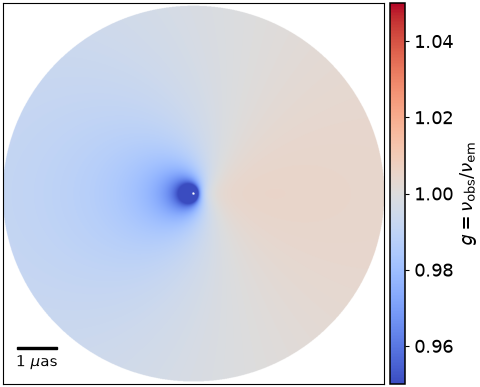

In [3]:
gfactor = source.transfer.gfactor.detach().cpu().numpy()
hit = source.transfer.hit.detach().cpu().numpy()
gfactor_display = np.where(hit, gfactor, np.nan)
g_delta = max(float(np.nanpercentile(np.abs(gfactor_display - 1.0), 99.5)), 0.05)
half_source_uas = 0.5 * source_grid.field_of_view_uas[0]

redshift_figure, redshift_axis = plt.subplots(figsize=(5.0, 4.2))
redshift_artist = redshift_axis.imshow(
    gfactor_display,
    origin="lower",
    extent=(-half_source_uas, half_source_uas) * 2,
    cmap="coolwarm",
    vmin=1.0 - g_delta,
    vmax=1.0 + g_delta,
)
mcp.add_scale_bar(redshift_axis, 1.0, label=r"1 $\mu$as", color="black")
mcp.hide_image_axes(redshift_axis)
mcp.panel_colorbar(
    redshift_figure,
    redshift_axis,
    redshift_artist,
    label=r"$g=\nu_{\rm obs}/\nu_{\rm em}$",
)
redshift_figure.tight_layout()


## Observer-transfer and continuum-lag maps

The same live Kerr calculation registers every observer pixel to an emission radius and azimuth on the disk. It also records the relative disk-to-observer propagation delay. The continuum lag adds the axial lamp-to-disk travel time and then sets zero at the earliest physically responsive disk element. These maps are useful outputs on their own for continuum reverberation, non-axisymmetric emission models, and checks of the image-to-disk coordinate mapping.


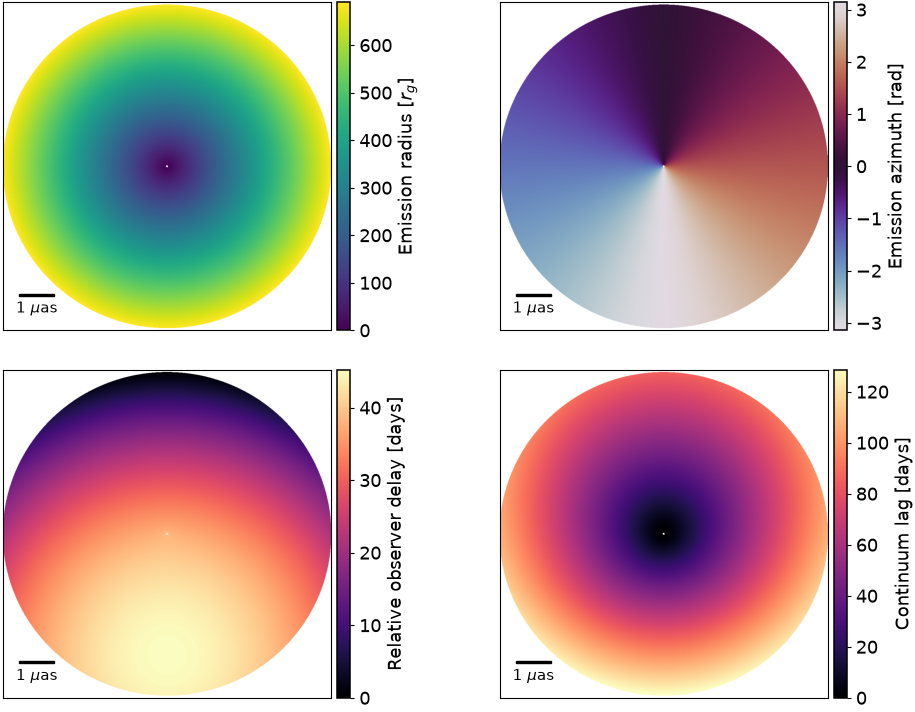

In [4]:
radius_rg = source.transfer.radius_rg.detach().cpu().numpy()
azimuth_rad = source.transfer.emission_azimuth_rad.detach().cpu().numpy()
observer_delay_days = source.transfer.relative_delay_days.detach().cpu().numpy()
continuum_lag_days = source.delay_days.detach().cpu().numpy()
response_temperature4 = source.response_temperature4.detach().cpu().numpy()
physical_disk = (
    hit & np.isfinite(radius_rg) & (radius_rg >= isco_rg)
    & (radius_rg <= disk_outer_rg)
)
responsive_disk = physical_disk & np.isfinite(response_temperature4) & (response_temperature4 > 0.0)

transfer_maps = (
    (np.where(physical_disk, radius_rg, np.nan), 'viridis', 0.0, disk_outer_rg, r'Emission radius [$r_g$]'),
    (np.where(physical_disk, azimuth_rad, np.nan), 'twilight', -np.pi, np.pi, 'Emission azimuth [rad]'),
    (np.where(physical_disk, observer_delay_days, np.nan), 'magma', 0.0, None, 'Relative observer delay [days]'),
    (np.where(responsive_disk, continuum_lag_days, np.nan), 'magma', 0.0, None, 'Continuum lag [days]'),
)

transfer_figure, transfer_axes = plt.subplots(2, 2, figsize=(9.2, 7.4))
for axis, (values, cmap, lower, upper, label) in zip(transfer_axes.flat, transfer_maps):
    if upper is None:
        upper = float(np.nanpercentile(values, 99.8))
    artist = axis.imshow(
        values, origin='lower', extent=(-half_source_uas, half_source_uas) * 2,
        cmap=cmap, vmin=lower, vmax=upper,
    )
    mcp.add_scale_bar(axis, 1.0, label=r'1 $\mu$as', color='black')
    mcp.hide_image_axes(axis)
    mcp.panel_colorbar(transfer_figure, axis, artist, label=label)
transfer_figure.subplots_adjust(left=0.03, right=0.95, bottom=0.04, top=0.98, wspace=0.42, hspace=0.12)
transfer_figure.savefig(
    OUTPUT_DIRECTORY / 'gr_observer_transfer_and_continuum_lag_maps.png',
    dpi=220, bbox_inches='tight', facecolor='white',
)


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\reprocessing.py:570: CompilationWarning: Compilation event 4: preparing a new torch.compile specialization for retarded thermal driving on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  temperature4, _ = run_tensor_kernel(


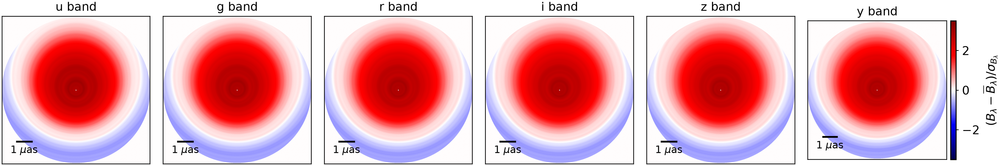

In [5]:
# Accumulate the ten-year temporal statistics without retaining a full
# [time, y, x, band] cube. The helper selects the brightest epoch and applies
# one wavelength-independent Kerr image support to every band.
display_times = torch.arange(
    0.0, 3650.0 + 12.5, 25.0,
    dtype=display_dtype, device=runtime.device,
)
disk_summary = mcp.standardize_source_over_time(
    source, display_times,
    batch_size=4, dtype=display_dtype, device=runtime.device,
)
brightness = disk_summary.representative
figure, axes = mcp.plot_standardized_source_bands(
    disk_summary, source_grid, geometry.band_names,
    scale_bar_uas=1.0, figsize=(15.6, 2.7),
)
disk_panel_path = OUTPUT_DIRECTORY / "relativistic_disk_brightness_panels.png"
figure.savefig(disk_panel_path, dpi=220, bbox_inches="tight", facecolor="white")
plt.close(figure)
from IPython.display import Image, display
display(Image(filename=str(disk_panel_path)))


## Variable relativistic disk animation

This animation shows the i band from the six-band source above, using the same physical disk support, per-pixel temporal mean and standard deviation, and fixed $[-3.5,3.5]$ color scale. The full disk colormap is preserved without dithering, which can resemble pixel-scale fluctuations. The source is evaluated every 25 days for display and can still be evaluated daily for light curves. This is intrinsic reverberation without microlensing. Both GIFs show the first eight years to keep the notebook compact. The calculations and static plots retain the full ten-year sequence.

Below, the microlensed transfer functions use stellar seed 11 with bulk-velocity seed 0, matching the Q2237 light-curve tutorial. We selected this realization for its dense caustic network near the disk, not as a typical crossing rate. No lens, source, or velocity parameters were changed to produce that selection.


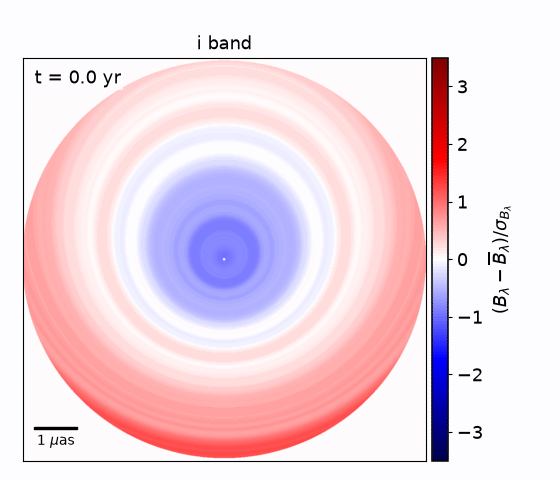

Wrote relativistic_transfer_output\variable_relativistic_disk.gif
Frames: 117


In [6]:
animation_end_days = 8 * 365.0
animation_times = display_times[display_times <= animation_end_days]
disk_animation_path = mcp.animate_standardized_source_bands(
    source,
    animation_times,
    disk_summary,
    source_grid,
    OUTPUT_DIRECTORY / "variable_relativistic_disk.gif",
    bands="i",  # one band for a larger, more readable animation
    batch_size=4,
    fps=8,
    scale_bar_uas=1.0,
    dtype=display_dtype,
    device=runtime.device,
)
display(Image(filename=str(disk_animation_path)))
print("Wrote", disk_animation_path)
print("Frames:", len(animation_times))


In [7]:
# Use the same seeded Q2237 image-B-like Salpeter population as the main
# production tutorial. The system derives the circular stellar aperture,
# star count, masses, angular velocities, and lens-plane integration bounds.
macro = mc.MacroLens(
    convergence=0.391, shear=0.391,
    shear_angle_deg=141.73, smooth_matter_fraction=0.0,
)
population = mc.StellarPopulation.salpeter(
    mean_mass_solar=0.3,
    mass_ratio=100.0,
    kinematics=mc.SkyProjectedKinematics(
        ra_deg=340.126125, dec_deg=3.358611,
        stellar_dispersion_km_s=170.0,
        peculiar_velocity_dispersion_km_s=235.0,
        include_cmb_dipole=True, seed=0,
    ),
)
system = mc.MicrolensingSystem(
    lens_redshift=lens_redshift,
    source_redshift=source_redshift,
    H0=H0,
    Om0=Om0,
    macro=macro,
    source=source,
    stellar_population=population,
    duration_days=3650.0,
    light_loss=0.01,
    safety_scale=1.5,
    seed=11,  # caustic-rich stellar realization shared with the Q2237 GIF
    runtime=runtime_config,
)
realization = system.realize()
# Source contours and magnification maps must use identical angular fields.
np.testing.assert_allclose(
    source_grid.field_of_view_uas, realization.source_grid.field_of_view_uas,
    rtol=1.0e-6, atol=0.0,
)
trajectory = mc.LinearTrajectory()
ray_count = 10_000_000 if use_cuda else 262_144
method = mc.production_ipm_config(rays=ray_count)
schedule = mc.production_dynamic_config()
print('Stars:', len(realization.stars))
print('IPM preset:', method)
print('Dynamic preset:', schedule)
map_times = torch.arange(0.0, 3650.0 + 12.5, 25.0)
finite_delays = source.delay_days[source.transfer.hit]
delay_max = max(20.0, float(finite_delays.max().cpu()) + 2.0)
native_edges = torch.arange(0.0, delay_max + 0.5, 0.5, device=runtime.device, dtype=runtime.dtype)
delay_edges = torch.arange(0.0, float(native_edges[-1]) + 0.125, 0.25, device=runtime.device, dtype=runtime.dtype)
# CDF reconstruction is numerical rebinning, not a plotting filter.
steady = system.steady_transfer_function(delay_edges, native_delay_edges_days=native_edges)

retained_maps = []
def retain_transfer_map(index, magnification_map):
    # Retain the calculated 1024-square map without pixel averaging.
    retained_maps.append(magnification_map.values.detach().cpu())

series = system.transfer_functions(
    map_times.tolist(), delay_edges, native_delay_edges_days=native_edges,
    method=method, trajectory=trajectory, schedule=schedule,
    map_observer=retain_transfer_map,
)
print("Transfer-function epochs:", len(map_times))
print("Delivered dynamic response time [s]:", series.timing.delivered_seconds)


Stars: 3830
IPM preset: IPMConfig(rays=10000000, scout_ratio=2, refinement=2, virtual_refinement=4, tiled=True, scout_halo_pixels=0.0, scout_dilation_cells=1, scout_trace_centers=False, dual_scout_scalar_correction=True, cell_chunk_size=524288, compact_sparse_nodes=True, far_field_approx=FarFieldApproxConfig(enabled=True, cells_per_axis=16, nodes_per_cell_axis=8, exact_radius_cells=1.0, taylor_order=4, center_translation_order=10))
Dynamic preset: DynamicConfig(temporal_batch_size=49, light_curve_batch_size=None, fused_temporal_ipm=True, scout_refresh_frames=10, tuning=AutoTuningConfig(enabled=False, tune_temporal_batch=True, tune_spatial_chunk=True, temporal_candidates=(1, 4, 8, 12, 16, 20, 24, 32, 40, 49, 64), spatial_candidates=(16384, 32768, 65536, 131072, 262144, 524288, 1048576), warmup_runs=1, benchmark_runs=2, maximum_trial_frames=64, memory_fraction=None, memory_headroom_fraction=0.95, verify_numerics=True, verification_rtol=5e-05, verification_atol=5e-06, cache=True), minimum

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\response_rebin.py:153: CompilationWarning: Compilation event 5: preparing a new torch.compile specialization for CDF/PCHIP response reconstruction on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  result, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\lens\models.py:842: CompilationWarning: Compilation event 6: preparing a new torch.compile specialization for specular stellar-boundary evolution on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  positions, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:920: CompilationWarning: Compilation event 7: preparing a new Triton specialization for IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1319: CompilationWarning: Compilation event 8: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\response_rebin.py:153: CompilationWarning: Compilation event 9: preparing a new torch.compile specialization for CDF/PCHIP response reconstruction on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  result, _ = run_tensor_kernel(


Transfer-function epochs: 147
Delivered dynamic response time [s]: 4.9174051999580115


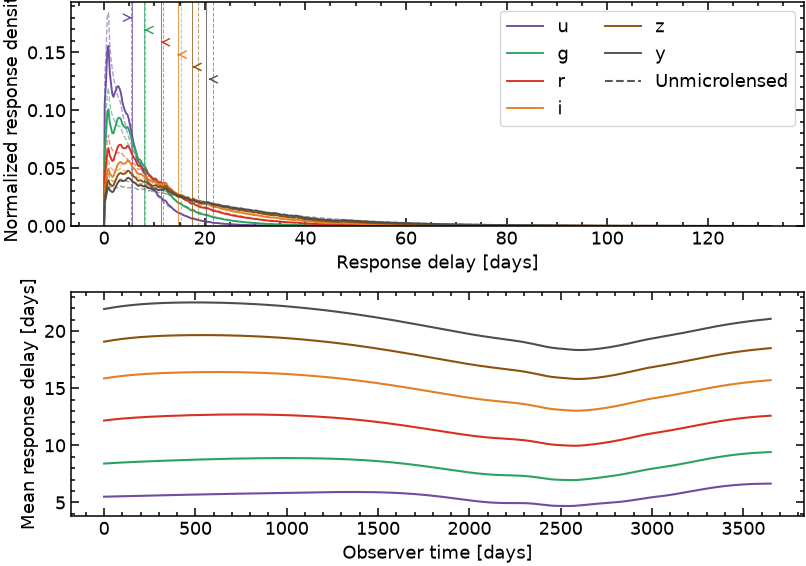

In [8]:
figure, axes = plt.subplots(2, 1, figsize=(8.4, 6.0), sharex=False)
band = "i"
band_index = series.band_names.index(band)
centers, steady_density = mcp.transfer_response_density(
    steady, include_zero_boundaries=True
)
series_density = np.stack([
    mcp.transfer_response_density(
        series, epoch=index, 
        include_zero_boundaries=True,
    )[1]
    for index in range(len(map_times))
])
representative = len(map_times) // 2
colors = mcp.band_colors(series.band_names)
for index, name in enumerate(series.band_names):
    color = colors[name]
    axes[0].plot(centers, steady_density[:, index], color=color, linestyle="--", linewidth=1.0, alpha=0.55)
    axes[0].plot(centers, series_density[representative, :, index], color=color, linewidth=1.35, label=name)
    steady_lag = float(steady.mean_delays_days[index].cpu())
    micro_lag = float(series.mean_delays_days[representative, index].cpu())
    level = 0.93 - 0.055 * index
    axes[0].axvline(steady_lag, color=color, linestyle="--", linewidth=0.75, alpha=0.55)
    axes[0].axvline(micro_lag, color=color, linewidth=0.75, alpha=0.75)
    axes[0].annotate(
        "", xy=(micro_lag, level), xytext=(steady_lag, level),
        xycoords=("data", "axes fraction"), textcoords=("data", "axes fraction"),
        arrowprops={"arrowstyle": "->", "color": color, "linewidth": 1.0},
    )
axes[0].plot([], [], color="0.35", linestyle="--", label="Unmicrolensed")
axes[0].set(xlabel="Response delay [days]", ylabel="Normalized response density", ylim=(0.0, None))
axes[0].legend(frameon=True, ncol=2, loc="upper right")
mcp.finish_axis(axes[0])

for index, name in enumerate(series.band_names):
    axes[1].plot(map_times.cpu(), series.mean_delays_days[:, index].detach().cpu(), color=colors[name], label=name)
axes[1].set(xlabel="Observer time [days]", ylabel="Mean response delay [days]")
mcp.finish_axis(axes[1])
figure.tight_layout()
transfer_panel_path = OUTPUT_DIRECTORY / "relativistic_transfer_functions.png"
figure.savefig(transfer_panel_path, dpi=220, bbox_inches="tight", facecolor="white")


Wrote relativistic_transfer_output\microlensed_transfer_functions.gif


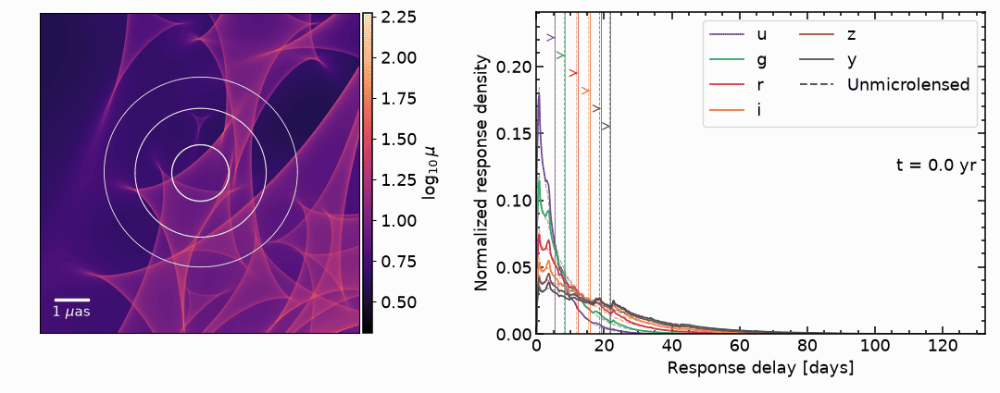

In [9]:
centers, _ = mcp.transfer_response_density(
    series, epoch=0, include_zero_boundaries=True
)
density = np.stack([
    mcp.transfer_response_density(
        series, epoch=index,
        include_zero_boundaries=True,
    )[1]
    for index in range(len(map_times))
])
steady_centers, steady_density = mcp.transfer_response_density(
    steady, include_zero_boundaries=True
)
colors = mcp.band_colors(series.band_names)
log_maps = torch.log10(torch.stack(retained_maps).clamp_min(1.0e-2)).numpy()
map_vmin, map_vmax = float(np.nanmin(log_maps)), float(np.nanmax(log_maps))
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.25), gridspec_kw={"width_ratios": (1.0, 1.35)})
map_artist = axes[0].imshow(
    log_maps[0], origin="lower", extent=source_grid.bounds_uas,
    cmap="magma", vmin=map_vmin, vmax=map_vmax, interpolation="bilinear",
)

# Overlay contours of the static y-band source at its physical source-plane
# position.  The contour is not folded into the magnification map.
y_index = source.geometry.band_names.index("y")
y_source = np.asarray(brightness[:, :, y_index], dtype=np.float64)
# The manuscript contours use a display-only Gaussian smoothing and
# enclosed-flux levels.  This suppresses pixel-staircase contours without
# changing either the source or the microlensing calculation.
contour_sigma_pixels = 3.0 * y_source.shape[0] / 256.0
smoothed_y = gaussian_filter(y_source, contour_sigma_pixels, mode="nearest")
y_levels = mcp.enclosed_flux_contour_levels(
    smoothed_y, fractions=(0.68, 0.95, 0.99),
)
x0, x1, y0, y1 = source_grid.bounds_uas
source_x = np.linspace(x0, x1, y_source.shape[1])
source_y = np.linspace(y0, y1, y_source.shape[0])
axes[0].contour(
    source_x, source_y, smoothed_y, levels=y_levels, colors="white",
    linewidths=(0.65, 0.8, 1.0), alpha=0.9,
)
mcp.add_scale_bar(axes[0], 1.0, label=r"1 $\mu$as", color="white")
mcp.hide_image_axes(axes[0])
mcp.panel_colorbar(figure, axes[0], map_artist, label=r"$\log_{10}\mu$", size="3%", pad=0.035)

lines, micro_lag_lines, lag_arrows = [], [], []
for index, name in enumerate(series.band_names):
    color = colors[name]
    axes[1].plot(
        steady_centers, steady_density[:, index], color=color,
        linestyle="--", linewidth=0.9, alpha=0.55,
    )
    line, = axes[1].plot(centers, density[0, :, index], color=color, label=name, linewidth=1.25)
    lines.append(line)
    axes[1].axvline(
        float(steady.mean_delays_days[index].cpu()), color=color,
        linestyle="--", linewidth=0.7, alpha=0.55,
    )
    micro_lag_lines.append(
        axes[1].axvline(float(series.mean_delays_days[0, index].cpu()), color=color, linewidth=0.7, alpha=0.75)
    )
    lag_arrows.append(None)
axes[1].plot([], [], color="0.35", linestyle="--", label="Unmicrolensed")
time_text = axes[1].text(
    0.98, 0.52, "", transform=axes[1].transAxes, ha="right", va="center",
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 1.5},
)
axes[1].set(
    xlim=(0.0, float(centers.max())), ylim=(0.0, 1.05 * float(max(density.max(), steady_density.max()))),
    xlabel="Response delay [days]", ylabel="Normalized response density",
)
axes[1].legend(frameon=True, ncol=2, loc="upper right")
mcp.finish_axis(axes[1])
figure.subplots_adjust(left=0.04, right=0.985, bottom=0.15, top=0.97, wspace=0.42)

rendered_frames = []
for frame_index in range(int((map_times <= animation_end_days).sum())):
    map_artist.set_data(log_maps[frame_index])
    for band_index, line in enumerate(lines):
        line.set_ydata(density[frame_index, :, band_index])
        micro_lag = float(series.mean_delays_days[frame_index, band_index].cpu())
        steady_lag = float(steady.mean_delays_days[band_index].cpu())
        micro_lag_lines[band_index].set_xdata([micro_lag, micro_lag])
        if lag_arrows[band_index] is not None:
            lag_arrows[band_index].remove()
        level = 0.92 - 0.055 * band_index
        lag_arrows[band_index] = axes[1].annotate(
            "", xy=(micro_lag, level), xytext=(steady_lag, level),
            xycoords=("data", "axes fraction"), textcoords=("data", "axes fraction"),
            arrowprops={"arrowstyle": "->", "color": colors[series.band_names[band_index]], "linewidth": 0.9},
        )
    time_text.set_text(f"t = {float(map_times[frame_index]) / 365.0:.1f} yr")
    figure.canvas.draw()
    rendered_frames.append(np.asarray(figure.canvas.buffer_rgba())[..., :3].copy())
gif_path = OUTPUT_DIRECTORY / "microlensed_transfer_functions.gif"
mcp.save_fixed_palette_gif(rendered_frames, gif_path, fps=8, dither=False)
plt.close(figure)
print("Wrote", gif_path)
try:
    from IPython.display import Image, display
    display(Image(filename=str(gif_path)))
except ImportError:
    pass


## Continuum reverberation without microlensing

The relativistic source above can also be used independently of every
microlensing solver. We reuse the same traced Kerr disk and driving signal,
then integrate its physical surface brightness directly.


## Steady relativistic response

The transfer function is normalized probability mass per delay bin.  Delays
are measured relative to the earliest retained lamp-to-disk-to-observer path, so
the causal response is exactly zero for negative relative delay and is pinned
to zero at the plotted origin.  The plotting helper divides the bin values by their widths to show response
density. It applies no display-only smoothing. CDF/PCHIP reconstruction is
part of the numerical response calculation.

Displayed causal response support: 0--132.0 days
The zero point is the earliest retained lamp--disk--observer path.


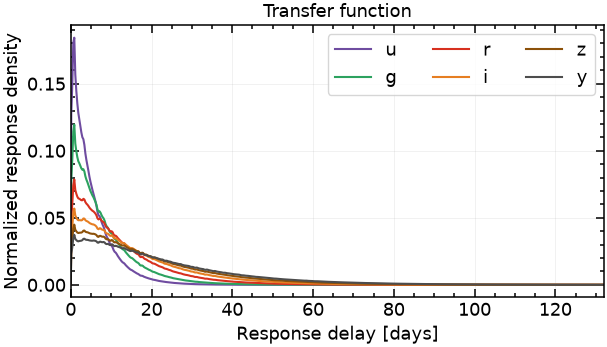

In [10]:
transfer = mc.steady_transfer_function(source, delay_edges, native_delay_edges_days=native_edges)
plot_delay, plot_density = mcp.transfer_response_density(
    transfer, include_zero_boundaries=True
)
assert plot_delay[0] == 0.0 and (plot_density[0] == 0.0).all()
figure, ax = mcp.plot_transfer_function(transfer)
ax.set_xlim(0.0, delay_max)
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / "continuum_reverberation_transfer.png", dpi=220, bbox_inches="tight", facecolor="white")
print(f"Displayed causal response support: 0--{delay_max:.1f} days")
print("The zero point is the earliest retained lamp--disk--observer path.")


## Daily driving and reprocessed continuum light curves

The driver is evaluated every day.  Each disk pixel responds at its own Kerr
and lamppost delay, after which the observer-screen intensity is integrated.
The integrated physical fluxes are converted directly to AB magnitudes. No relative-
magnitude shorthand is used.

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\reprocessing.py:570: CompilationWarning: Compilation event 10: preparing a new torch.compile specialization for retarded thermal driving on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  temperature4, _ = run_tensor_kernel(
C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:229: CompilationWarning: Compilation event 11: preparing a new Triton specialization for thermal spectral photometry on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  fast_result = triton_th

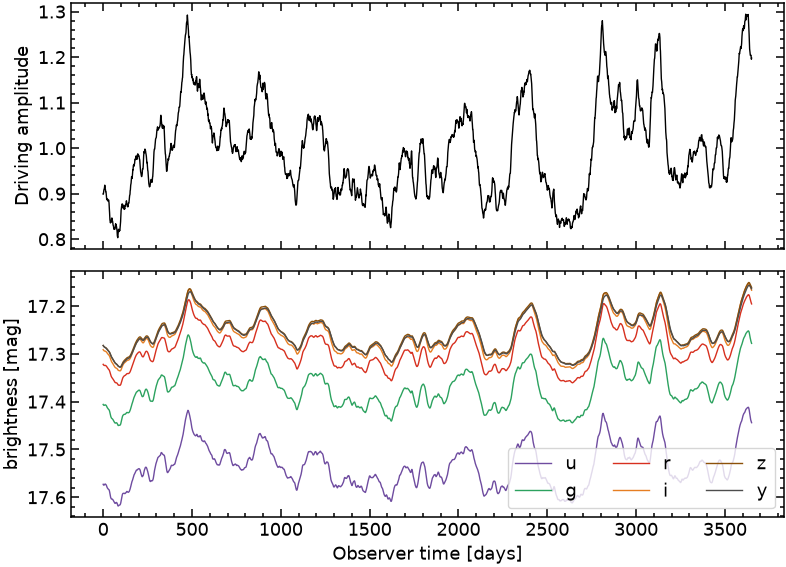

In [11]:
times = torch.arange(
    0.0, 3651.0, device=runtime.device, dtype=runtime.dtype
)
unlensed_curve = mc.source_light_curve(
    source, times, batch_size=16, device=runtime.device, dtype=runtime.dtype
)
driver_values = driver.amplitudes(
    times, bands=1, device=runtime.device, dtype=runtime.dtype,
)[:, 0].detach().cpu()
magnitudes = mc.flux_to_magnitude(unlensed_curve.flux).detach().cpu()
colors = mcp.band_colors(geometry.band_names)
figure, axes = plt.subplots(2, 1, figsize=(8.2, 6.0), sharex=True)
axes[0].plot(times.cpu(), driver_values, color="black", linewidth=1.0)
axes[0].set_ylabel("Driving amplitude")
for index, band in enumerate(geometry.band_names):
    axes[1].plot(
        times.cpu(), magnitudes[:, index], color=colors[band],
        label=band, linewidth=1.0,
    )
axes[1].invert_yaxis()
axes[1].set(xlabel="Observer time [days]", ylabel="brightness [mag]")
axes[1].legend(ncol=3, frameon=True)
for axis in axes:
    mcp.finish_axis(axis)
figure.tight_layout()
